# Week 10 — Local Search and Genetic Algorithms

**Lesson plan:** [`../weeks/week-10.md`](../weeks/week-10.md) · **Slides:** [`../slides/week-10/deck.md`](../slides/week-10/deck.md)

Live coding, 25 minutes: hill climbing failing (8) · simulated annealing (7) ·
a GA on knapsack (10).

> **Hill climbing and SA are not in the original deck.** Without them a GA looks
> like magic rather than one point in a design space.

In [17]:
import math
import random
import numpy as np
import matplotlib
%matplotlib inline
import matplotlib.pyplot as plt

SEED = 20250806
print("numpy", np.__version__)

numpy 1.26.4


## 1 · Hill climbing on 8-queens

State: one queen per column, `state[c] = row`. Value: **negative** number of
attacking pairs, so 0 is a solution and we are maximizing.

In [2]:
N = 8

def conflicts(state):
    c = 0
    for i in range(len(state)):
        for j in range(i + 1, len(state)):
            if state[i] == state[j] or abs(state[i] - state[j]) == j - i:
                c += 1
    return c


def value(state):
    return -conflicts(state)


def neighbors(state):
    """Move one queen to another row in its own column."""
    out = []
    for col in range(len(state)):
        for row in range(N):
            if row != state[col]:
                s = list(state)
                s[col] = row
                out.append(tuple(s))
    return out


def show_board(state):
    for r in range(N):
        print(" ".join("Q" if state[c] == r else "." for c in range(N)))


rng = random.Random(SEED)
s = tuple(rng.randrange(N) for _ in range(N))
print(f"random start: {conflicts(s)} attacking pairs")
show_board(s)

random start: 13 attacking pairs
. . . . . Q . .
. . . . . . . .
. . . . . . . .
. Q Q . Q . Q .
. . . Q . . . Q
Q . . . . . . .
. . . . . . . .
. . . . . . . .


## 2 · Steepest-ascent hill climbing, and its three failure modes

In [3]:
def hill_climb(state, allow_sideways=0):
    """Returns (state, reason, steps). allow_sideways = max equal-value moves."""
    sideways = 0
    steps = 0
    while True:
        nbrs = neighbors(state)
        best = max(nbrs, key=value)
        if value(best) > value(state):
            state, sideways = best, 0
        elif value(best) == value(state) and sideways < allow_sideways:
            state, sideways = best, sideways + 1     # PLATEAU move
        else:
            reason = "solved" if conflicts(state) == 0 else "stuck"
            return state, reason, steps
        steps += 1


def trial(n_runs=100, allow_sideways=0, seed=SEED):
    rng = random.Random(seed)
    wins = 0
    total_steps = 0
    for _ in range(n_runs):
        start = tuple(rng.randrange(N) for _ in range(N))
        end, reason, steps = hill_climb(start, allow_sideways)
        total_steps += steps
        wins += (reason == "solved")
    return wins / n_runs, total_steps / n_runs


for sideways in (0, 10, 100):
    rate, steps = trial(100, sideways)
    label = "no sideways moves" if sideways == 0 else f"up to {sideways} sideways"
    print(f"  {label:<22} success {rate:>6.0%}   avg steps {steps:>6.1f}")

  no sideways moves      success    19%   avg steps    3.3
  up to 10 sideways      success    36%   avg steps   10.2
  up to 100 sideways     success    36%   avg steps   66.0


### ⚠️ Understanding the failure mode told us the fix

Plain steepest-ascent gets stuck most of the time. Allowing **sideways moves on
plateaus** transforms it — from one change to how one failure mode is handled.

| Failure mode | What it looks like | Why gradient thinking fails |
|---|---|---|
| **Local optimum** | every neighbour is worse | the signal says stop, and it is wrong |
| **Plateau / shoulder** | neighbours are **equal** | **no gradient information at all** |
| **Ridge** | improving needs a *combination* of moves | no single move improves |

The plateau is the one worth fixing here because 8-queens is *full* of shoulders:
long flat regions where progress is possible but invisible to a strict-improvement
rule.

In [4]:
# Random restarts: the other classic fix. Embarrassingly parallel, but it
# throws away everything learned so far.
def random_restart(max_restarts=50, seed=SEED):
    rng = random.Random(seed)
    for i in range(max_restarts):
        start = tuple(rng.randrange(N) for _ in range(N))
        end, reason, _ = hill_climb(start, allow_sideways=0)
        if reason == "solved":
            return end, i + 1
    return None, max_restarts


sol, restarts = random_restart()
print(f"random restarts needed: {restarts}")
print(f"conflicts: {conflicts(sol)}")
show_board(sol)

random restarts needed: 7
conflicts: 0
. . . . Q . . .
Q . . . . . . .
. . . . . . . Q
. . . Q . . . .
. Q . . . . . .
. . . . . . Q .
. . Q . . . . .
. . . . . Q . .


## 3 · Simulated annealing

Accept a worse move with probability `exp(ΔE / T)`. High `T` → random walk; low
`T` → hill climbing. **The schedule chooses where you are on that line, moment to
moment.**

In [5]:
def simulated_annealing(state, schedule, rng, max_steps=60_000, record=False):
    current = state
    trace = []
    for t in range(1, max_steps + 1):
        T = schedule(t)
        if T <= 1e-12:
            break
        candidate = rng.choice(neighbors(current))
        delta = value(candidate) - value(current)
        if delta > 0 or rng.random() < math.exp(delta / T):
            current = candidate
        if record:
            trace.append(value(current))
        if conflicts(current) == 0:
            break
    return current, trace


def exp_schedule(T0=2.0, decay=0.9995):
    return lambda t: T0 * (decay ** t)


rng = random.Random(SEED)
wins = 0
for _ in range(30):
    start = tuple(rng.randrange(N) for _ in range(N))
    end, _ = simulated_annealing(start, exp_schedule(), rng)
    wins += conflicts(end) == 0
print(f"SA success over 30 runs: {wins/30:.0%}")

SA success over 30 runs: 100%


### The accepted-value trace — wild early, settling late

This picture makes the schedule's role obvious in a way words do not.

In [6]:
rng = random.Random(SEED)
start = tuple(rng.randrange(N) for _ in range(N))
end, trace = simulated_annealing(start, exp_schedule(), rng, max_steps=6000, record=True)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].plot(trace, lw=0.7)
ax[0].set_title("SA: accepted value over time")
ax[0].set_xlabel("step"); ax[0].set_ylabel("value (0 = solved)")

ts = np.arange(1, 6001)
ax[1].plot(ts, exp_schedule()(ts))
ax[1].set_title("temperature schedule"); ax[1].set_xlabel("step"); ax[1].set_ylabel("T")
plt.tight_layout()
plt.savefig("wk10-sa-trace.png", dpi=110)
print(f"final conflicts: {conflicts(end)}   (saved wk10-sa-trace.png)")

final conflicts: 0   (saved wk10-sa-trace.png)


### ⚠️ The guarantee, stated honestly

With a **sufficiently slow** schedule, SA converges to the global optimum with
probability 1.

"Sufficiently slow" means *slower than you can afford*. **So in practice you have
no guarantee.**

A theorem that is true and practically unreachable is a different thing from a
theorem you can rely on. By week 10 you should be making that distinction
automatically — it is scorecard axis 2.

## 4 · A genetic algorithm on knapsack

Population, tournament selection, uniform crossover, bit-flip mutation, elitism.
**Every parameter is a knob on exploration vs. exploitation.**

In [14]:
def make_knapsack(n_items=100, seed=SEED):
    rng = random.Random(seed)
    weights = [rng.randint(1, 60) for _ in range(n_items)]
    values  = [rng.randint(1, 100) for _ in range(n_items)]
    cap = sum(weights) // 3
    return weights, values, cap


WEIGHTS, VALUES, CAP = make_knapsack()
MAXV = max(VALUES)


def true_value(genome):
    """What the solution is actually worth. 0 if it does not fit."""
    w = sum(x * wt for x, wt in zip(genome, WEIGHTS))
    return 0 if w > CAP else sum(x * v for x, v in zip(genome, VALUES))


def fitness(genome):
    """PENALTY fitness: overweight solutions are punished in proportion to the
    overage, not flattened to zero.

    This matters more than it looks. With a hard zero, every random genome in a
    100-item instance is infeasible and scores 0 -- the landscape is FLAT and
    selection has nothing to work with. Shaping the penalty gives the search a
    gradient back toward feasibility.

    Fitness-function design is part of the algorithm, not a detail."""
    w = sum(x * wt for x, wt in zip(genome, WEIGHTS))
    v = sum(x * val for x, val in zip(genome, VALUES))
    if w <= CAP:
        return v
    return max(0.0, v - 2.0 * MAXV * (w - CAP))


def knapsack_optimum():
    """Exact DP optimum -- so we can report % of optimum, not just 'a number'."""
    best = [0] * (CAP + 1)
    for wt, v in zip(WEIGHTS, VALUES):
        for c in range(CAP, wt - 1, -1):
            best[c] = max(best[c], best[c - wt] + v)
    return max(best)


OPT = knapsack_optimum()


def genetic_algorithm(pop_size=60, mutation=0.02, tournament=3,
                      max_evals=20_000, elitism=2, rng=None, record=False,
                      density=0.15):
    rng = rng or random.Random(SEED)
    n = len(WEIGHTS)
    # Seed SPARSE genomes -- a 50/50 random genome is wildly overweight.
    pop = [[1 if rng.random() < density else 0 for _ in range(n)]
           for _ in range(pop_size)]
    evals = 0
    scores = [fitness(g) for g in pop]; evals += pop_size
    best = max(true_value(g) for g in pop)
    trace, diversity = [], []

    while evals + pop_size <= max_evals:
        if record:
            trace.append(best)
            diversity.append(len({tuple(g) for g in pop}) / pop_size)

        ranked = sorted(zip(scores, pop), key=lambda kv: -kv[0])
        new_pop = [list(g) for _, g in ranked[:elitism]]

        def pick():
            cands = [rng.randrange(pop_size) for _ in range(tournament)]
            return pop[max(cands, key=lambda i: scores[i])]

        while len(new_pop) < pop_size:
            p1, p2 = pick(), pick()
            child = [p1[i] if rng.random() < 0.5 else p2[i] for i in range(n)]
            child = [1 - b if rng.random() < mutation else b for b in child]
            new_pop.append(child)

        pop = new_pop
        scores = [fitness(g) for g in pop]; evals += pop_size
        best = max(best, max(true_value(g) for g in pop))   # TRUE value, always

    return best, trace, diversity


best, _, _ = genetic_algorithm()
print(f"knapsack: {len(WEIGHTS)} items, capacity {CAP}")
print(f"exact DP optimum : {OPT}")
print(f"GA best value    : {best}   ({best/OPT:.1%} of optimum)")
print("""
Reporting '% of optimum' instead of a bare number is worth the extra ten lines of
DP. 'The GA scored 3594' is uninterpretable; '99.1% of optimum' is a result.
For most real problems you cannot compute the optimum -- which is exactly why you
should do it on the small ones, to calibrate how much to trust the method.""")

knapsack: 100 items, capacity 937
exact DP optimum : 3625
GA best value    : 3613   (99.7% of optimum)

Reporting '% of optimum' instead of a bare number is worth the extra ten lines of
DP. 'The GA scored 3594' is uninterpretable; '99.1% of optimum' is a result.
For most real problems you cannot compute the optimum -- which is exactly why you
should do it on the small ones, to calibrate how much to trust the method.


## 5 · ⚠️ Break it twice — the parameters *select the behaviour*

    mutation  best value   final diversity
  ------------------------------------------
         0.0        2656               2%
        0.02        3613              98%
         0.5        2297             100%


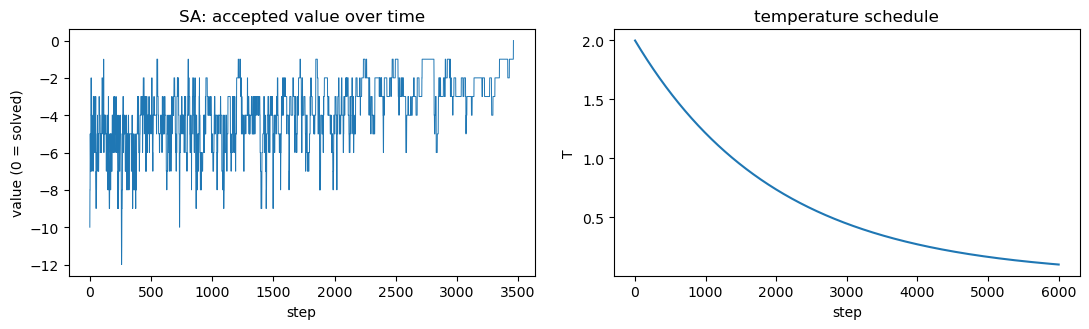

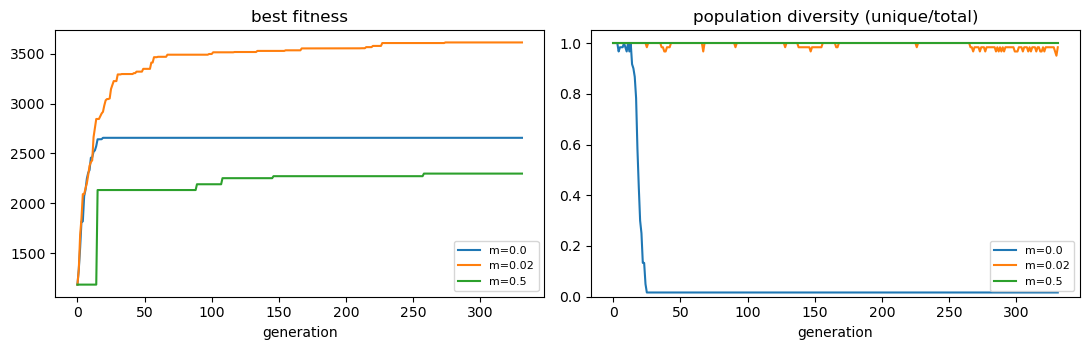

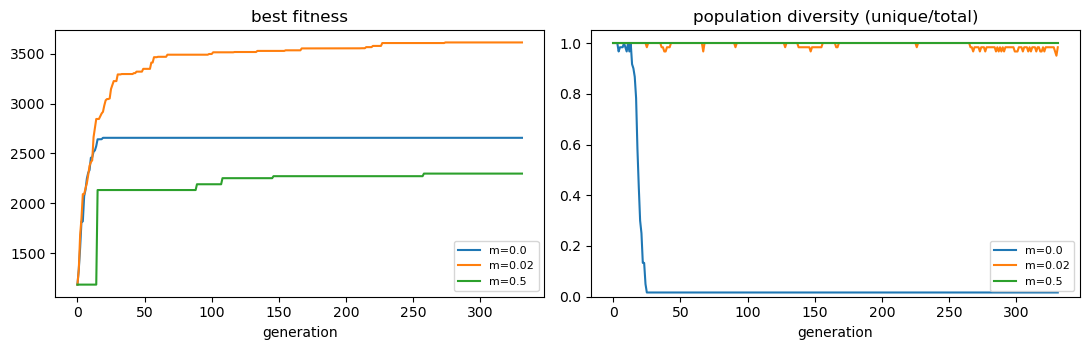

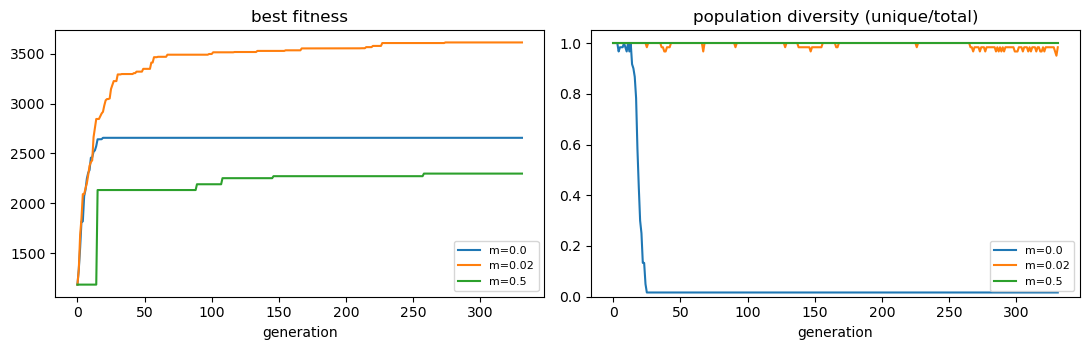

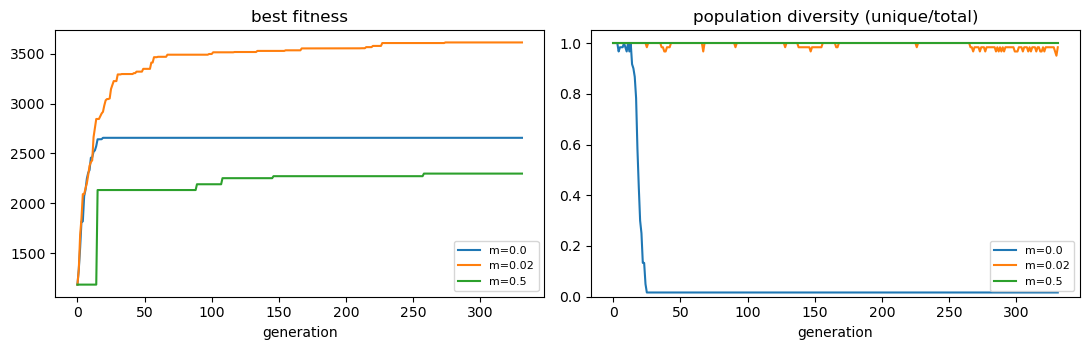


mutation = 0.0  -> diversity collapses, improvement STOPS. Crossover alone cannot
                   invent an allele the population has already lost.
                   DIVERSITY IS NOT OPTIONAL.
mutation = 0.5  -> diversity stays maximal and nothing converges. You have paid
                   for a random search with extra steps.

The parameters are not decoration. They select the algorithm's ACTUAL BEHAVIOUR.


In [18]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))

settings = [(0.0, "mutation 0.0 -- collapses to a clone"),
            (0.02, "mutation 0.02 -- healthy"),
            (0.5, "mutation 0.5 -- random search")]

print(f"  {'mutation':>10}{'best value':>12}{'final diversity':>18}")
print("  " + "-" * 42)
for m, label in settings:
    b, trace, div = genetic_algorithm(mutation=m, rng=random.Random(SEED), record=True)
    ax[0].plot(trace, label=f"m={m}")
    ax[1].plot(div, label=f"m={m}")
    print(f"  {m:>10}{b:>12}{div[-1]:>17.0%}")

ax[0].set_title("best fitness"); ax[0].set_xlabel("generation"); ax[0].legend(fontsize=8)
ax[1].set_title("population diversity (unique/total)")
ax[1].set_xlabel("generation"); ax[1].set_ylim(0, 1.05); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig("wk10-ga-mutation.png", dpi=110)
plt.show()
print("""
mutation = 0.0  -> diversity collapses, improvement STOPS. Crossover alone cannot
                   invent an allele the population has already lost.
                   DIVERSITY IS NOT OPTIONAL.
mutation = 0.5  -> diversity stays maximal and nothing converges. You have paid
                   for a random search with extra steps.

The parameters are not decoration. They select the algorithm's ACTUAL BEHAVIOUR.""")

## 6 · ⚠️ Fixed *evaluations*, not fixed *generations*

Population 100 for 50 generations and population 20 for 250 generations are the
**same compute**. Comparing at equal generations **silently favours large
populations.**

This is the methodological rule that makes week 11's bake-off honest.

In [19]:
print("Equal EVALUATION budget (20,000 fitness calls):")
print(f"  {'pop size':>10}{'generations':>13}{'best value':>12}{'% of opt':>11}")
print("  " + "-" * 48)
for pop in (20, 60, 200):
    b, trace, _ = genetic_algorithm(pop_size=pop, rng=random.Random(SEED), record=True)
    print(f"  {pop:>10}{len(trace):>13}{b:>12}{b/OPT:>10.1%}")

print("""
Small populations get many generations, large populations get few. Neither is
automatically better -- and if you had fixed GENERATIONS instead, pop=200 would
have silently used 10x the compute of pop=20 and "won".""")

Equal EVALUATION budget (20,000 fitness calls):
    pop size  generations  best value   % of opt
  ------------------------------------------------
          20          999        3592     99.1%
          60          332        3613     99.7%
         200           99        3548     97.9%

Small populations get many generations, large populations get few. Neither is
automatically better -- and if you had fixed GENERATIONS instead, pop=200 would
have silently used 10x the compute of pop=20 and "won".


## 7 · Honest comparison: is the GA even the right tool?

**A 2-opt-style hill climber often beats a naive GA at equal budget.** Run it and
find out, rather than assuming the biologically-inspired method wins.

In [10]:
def hc_knapsack(max_evals=20_000, rng=None):
    """Bit-flip hill climbing on the SAME evaluation budget.
    Starts from the empty knapsack, which is feasible."""
    rng = rng or random.Random(SEED)
    n = len(WEIGHTS)
    evals, best_overall = 0, 0
    while evals < max_evals:
        cur = [0] * n
        cur_f = fitness(cur); evals += 1
        improved = True
        while improved and evals < max_evals:
            improved = False
            for i in range(n):
                if evals >= max_evals:
                    break
                cur[i] ^= 1
                f = fitness(cur); evals += 1
                if f > cur_f:
                    cur_f, improved = f, True
                else:
                    cur[i] ^= 1
        best_overall = max(best_overall, true_value(cur))
        break        # a single climb already exhausts most of the budget
    return best_overall


ga_best, _, _ = genetic_algorithm(rng=random.Random(SEED))
hc_best = hc_knapsack(rng=random.Random(SEED))

print(f"  {'method':<28}{'best value':>12}{'% of opt':>11}")
print("  " + "-" * 51)
print(f"  {'GA (pop 60, m=0.02)':<28}{ga_best:>12}{ga_best/OPT:>10.1%}")
print(f"  {'hill climbing':<28}{hc_best:>12}{hc_best/OPT:>10.1%}")
print(f"  {'exact DP optimum':<28}{OPT:>12}{1.0:>10.1%}")
winner = "GA" if ga_best > hc_best else ("hill climbing" if hc_best > ga_best else "tie")
print(f"\n  at equal budget: {winner}")

print("""
Here the GA wins clearly, and the reason is instructive: one greedy climb from the
empty knapsack burns nearly the whole budget on a single trajectory and then has
nothing left to escape its local optimum. The GA spends the same evaluations across
many partial solutions and recombines them.

REPORT WHAT YOU MEASURE, INCLUDING WHEN IT CONTRADICTS THE LECTURE. On TSP with a
proper 2-opt neighbourhood, hill climbing frequently BEATS a naive GA at equal
budget -- the studio asks you to check, not to assume. A GA is not automatically
better for being biologically inspired.""")

  method                        best value   % of opt
  ---------------------------------------------------
  GA (pop 60, m=0.02)                 3613     99.7%
  hill climbing                       1993     55.0%
  exact DP optimum                    3625    100.0%

  at equal budget: GA

Here the GA wins clearly, and the reason is instructive: one greedy climb from the
empty knapsack burns nearly the whole budget on a single trajectory and then has
nothing left to escape its local optimum. The GA spends the same evaluations across
many partial solutions and recombines them.

REPORT WHAT YOU MEASURE, INCLUDING WHEN IT CONTRADICTS THE LECTURE. On TSP with a
proper 2-opt neighbourhood, hill climbing frequently BEATS a naive GA at equal
budget -- the studio asks you to check, not to assume. A GA is not automatically
better for being biologically inspired.


## 7½ · The same honest question, now on TSP

§7 ended on a promise: *"On TSP with a proper 2-opt neighbourhood, hill climbing
frequently BEATS a naive GA at equal budget."* Let's check it — on the **exact
30-city instance the studio uses** (seed `20250806`). Watch the demo here, then
run your hyperparameter study (§8) on the identical cities.

A TSP *tour* is a **permutation** of the city indices, and that one fact drives
everything: the natural neighbourhood is **2-opt** (reverse a segment — the result
is always still a permutation), and plain one-point crossover is a **trap**,
because splicing two permutations duplicates and drops cities.

In [20]:
# Self-contained copy of the studio's TSP (studios/week-10/localsearch.py), so the
# notebook and the studio agree on the SAME representation and the SAME instance.
class TSP:
    """Euclidean TSP. A tour is a permutation of city indices 0..n-1; the
    salesperson returns to the start. value = -tour length (we maximise value)."""

    def __init__(self, cities):
        self.cities = [tuple(c) for c in cities]
        self.n = len(self.cities)

    def dist(self, a, b):
        (x1, y1), (x2, y2) = self.cities[a], self.cities[b]
        return math.hypot(x1 - x2, y1 - y2)

    def length(self, tour):
        return sum(self.dist(tour[i], tour[(i + 1) % self.n]) for i in range(self.n))

    def value(self, tour):
        return -self.length(tour)

    def valid_tour(self, tour):
        return len(tour) == self.n and sorted(tour) == list(range(self.n))

    def random_tour(self, rng):
        t = list(range(self.n)); rng.shuffle(t); return t

    def nearest_neighbor_tour(self, start=0):
        """Greedy 'known-good' baseline: always hop to the nearest unvisited city."""
        unvisited = set(range(self.n))
        tour = [start]; unvisited.discard(start)
        while unvisited:
            last = tour[-1]
            nxt = min(unvisited, key=lambda c: self.dist(last, c))
            tour.append(nxt); unvisited.discard(nxt)
        return tour

    def neighbors(self, tour):
        return two_opt_neighbors(tour)


def two_opt_neighbors(tour):
    """Reverse segment tour[i..j] — always another valid permutation. This is why
    2-opt is the natural neighbourhood for a permutation problem."""
    n = len(tour)
    for i in range(n - 1):
        for j in range(i + 1, n):
            yield tour[:i] + tour[i:j + 1][::-1] + tour[j + 1:]


# Rebuild the studio's 30-city instance reproducibly from the shared seed. This is
# the SAME generator as studios/week-10/_generate_instances.py, so the coordinates
# are byte-for-byte the ones in studios/week-10/instances.json.
N_CITIES, FIELD = 30, 100.0
_ig = random.Random(SEED)
CITIES = [[round(_ig.uniform(0, FIELD), 2), round(_ig.uniform(0, FIELD), 2)]
          for _ in range(N_CITIES)]
tsp = TSP(CITIES)
nn_tour = tsp.nearest_neighbor_tour(start=0)
print(f"TSP instance: {tsp.n} cities (seed {SEED})")
print(f"nearest-neighbour (known-good) tour length: {tsp.length(nn_tour):.4f}")
print("matches studios/week-10/instances.json (470.1856): "
      f"{abs(tsp.length(nn_tour) - 470.1856) < 1e-3}")

TSP instance: 30 cities (seed 20250806)
nearest-neighbour (known-good) tour length: 470.1856
matches studios/week-10/instances.json (470.1856): True


Two methods on the **same evaluation budget** (the §6 rule), so the comparison is
honest:

- **2-opt hill climbing** with random restarts — reverse a segment, keep it if the
  tour got shorter.
- A **GA** with **order crossover (OX)** and **swap mutation** — the two operators
  that respect the permutation. (One-point crossover would produce invalid tours,
  which is why the studio has you write `validate_tour()` first.)

In [12]:
def tsp_hill_climb(tsp, rng, neighbors_fn=two_opt_neighbors, max_evals=20_000, start=None):
    """First-improvement 2-opt with random restarts, capped at an EVALUATION
    budget (each length() call is one evaluation). Restarts spend the remaining
    budget from a fresh random tour — this is what lets it escape a local optimum."""
    evals = 0
    best_tour, best_len = None, math.inf
    first = True
    while evals < max_evals:
        cur = start if (first and start is not None) else tsp.random_tour(rng)
        first = False
        cur_len = tsp.length(cur); evals += 1
        improved = True
        while improved and evals < max_evals:
            improved = False
            for nb in neighbors_fn(cur):
                if evals >= max_evals:
                    break
                nl = tsp.length(nb); evals += 1
                if nl < cur_len - 1e-9:
                    cur, cur_len, improved = nb, nl, True
                    break                     # first-improvement
        if cur_len < best_len:
            best_tour, best_len = cur, cur_len
    return best_tour, best_len


def order_crossover(p1, p2, rng):
    """OX: keep a contiguous slice of p1, fill the rest in p2's order. Preserves
    the permutation — the fix for the one-point-crossover trap."""
    n = len(p1)
    a, b = sorted(rng.sample(range(n), 2))
    child = [None] * n
    child[a:b + 1] = p1[a:b + 1]
    taken = set(p1[a:b + 1])
    fill = [c for c in p2 if c not in taken]
    k = 0
    for i in range(n):
        if child[i] is None:
            child[i] = fill[k]; k += 1
    return child


def swap_mutation(tour, rng):
    t = list(tour)
    i, j = rng.sample(range(len(t)), 2)
    t[i], t[j] = t[j], t[i]
    return t


def tsp_genetic_algorithm(tsp, crossover, mutation, rng, pop_size=50,
                          mutation_rate=0.1, tournament=5, elitism=2,
                          max_evals=20_000, use_crossover=True):
    """Generational GA (tournament + elitism) on an EQUAL EVALUATION budget."""
    pop = [tsp.random_tour(rng) for _ in range(pop_size)]
    fit = [tsp.value(t) for t in pop]
    evals = pop_size
    best_len = min(tsp.length(t) for t in pop)
    while evals + pop_size <= max_evals:
        ranked = sorted(zip(fit, pop), key=lambda kv: -kv[0])
        new_pop = [list(t) for _, t in ranked[:elitism]]

        def pick():
            cands = [rng.randrange(pop_size) for _ in range(tournament)]
            return pop[max(cands, key=lambda i: fit[i])]

        while len(new_pop) < pop_size:
            p1, p2 = pick(), pick()
            child = crossover(p1, p2, rng) if use_crossover else list(p1)
            if rng.random() < mutation_rate:
                child = mutation(child, rng)
            new_pop.append(child)

        pop = new_pop
        fit = [tsp.value(t) for t in pop]
        evals += pop_size
        best_len = min(best_len, min(tsp.length(t) for t in pop))
    return best_len


BUDGET = 20_000
hc_tour, hc_len = tsp_hill_climb(tsp, random.Random(SEED), max_evals=BUDGET)
ga_len = tsp_genetic_algorithm(tsp, order_crossover, swap_mutation,
                               random.Random(SEED), max_evals=BUDGET)
assert tsp.valid_tour(hc_tour)      # OX + 2-opt keep tours valid; one-point would not

print(f"Equal evaluation budget ({BUDGET:,} length() calls):")
print(f"  {'method':<28}{'tour length':>12}")
print("  " + "-" * 40)
print(f"  {'nearest-neighbour (greedy)':<28}{tsp.length(nn_tour):>12.1f}")
print(f"  {'2-opt hill climbing':<28}{hc_len:>12.1f}")
print(f"  {'GA (OX + swap, pop 50)':<28}{ga_len:>12.1f}")
winner = "hill climbing" if hc_len < ga_len else ("GA" if ga_len < hc_len else "tie")
print(f"\n  shortest tour at equal budget: {winner}")

Equal evaluation budget (20,000 length() calls):
  method                       tour length
  ----------------------------------------
  nearest-neighbour (greedy)         470.2
  2-opt hill climbing                443.2
  GA (OX + swap, pop 50)             530.7

  shortest tour at equal budget: hill climbing


### ⚠️ The result complicates the lecture — as promised

At an equal evaluation budget the **2-opt hill climber wins**: its tour is
shorter than the naive GA's — and the GA here does not even beat the greedy
nearest-neighbour baseline. This is the *opposite* of the knapsack result in §7,
where the GA won clearly.

There is no engineered GA victory here. The generic order-crossover + swap-mutation
GA spends its budget spread thin across a population, while 2-opt drives hard
downhill from each restart — and on a 30-city permutation landscape that focused
local search is simply the better use of the same evaluations.

**A GA is not better for being biologically inspired.** Which method wins depends
on the problem's structure and on the budget — which is exactly what the studio
(§8) asks you to measure, on *this same instance*, with error bars.

## 8 · Studio

Full hyperparameter study: population (20, 50, 100) × mutation (0.001, 0.01, 0.1)
× tournament (2, 5), **five seeds each**, **fixed evaluation budget**.

⚠️ **Every result needs error bars.** A stochastic algorithm reported from one run
is not a result — it is an anecdote.

⚠️ **For TSP, standard one-point crossover produces invalid tours** (repeated
cities). Permutation problems need **order crossover (OX)** or PMX. Write
`validate_tour()` *first*, so invalidity is detected immediately instead of after
fifteen minutes of debugging fitness.

In [13]:
# The error-bar pattern the studio requires.
def multi_seed(n_seeds=5, **kw):
    vals = [genetic_algorithm(rng=random.Random(SEED + i), **kw)[0]
            for i in range(n_seeds)]
    return float(np.mean(vals)), float(np.std(vals)), vals


print(f"  {'mutation':>10}{'mean':>10}{'std':>8}{'% of opt':>11}   runs")
print("  " + "-" * 60)
for m in (0.001, 0.01, 0.1):
    mean, std, vals = multi_seed(mutation=m)
    print(f"  {m:>10}{mean:>10.1f}{std:>8.1f}{mean/OPT:>10.1%}   {vals}")

print("""
Look at the spread before you believe any ranking. Two configurations whose error
bars overlap are not distinguishable by this experiment, and saying so is a
stronger result than picking a winner.""")

    mutation      mean     std   % of opt   runs
  ------------------------------------------------------------
       0.001    3335.2    88.9     92.0%   [3290, 3423, 3358, 3419, 3186]
        0.01    3614.0    10.3     99.7%   [3620, 3598, 3621, 3606, 3625]
         0.1    2968.0    84.7     81.9%   [3051, 2838, 3066, 2918, 2967]

Look at the spread before you believe any ranking. Two configurations whose error
bars overlap are not distinguishable by this experiment, and saying so is a
stronger result than picking a winner.
